
# Elliptic Bitcoin Dataset — Graph Neural Network Models

**Contributor:** Dhruvi Kadhiwala

This notebook implements and evaluates Graph Neural Network (GNN) models for detecting illicit transactions in the Elliptic Bitcoin dataset. The modeling pipeline includes loading the preprocessed transaction graph, implementing Graph Convolutional Network (GCN) and GraphSAGE architectures using PyTorch Geometric, addressing class imbalance through weighted cross-entropy loss, training models with early stopping, and evaluating performance on a chronologically separated validation set. Model performance is assessed using precision, recall, F1-score, and precision-recall area under the curve (PR-AUC), with additional visualizations including training curves, confusion matrices, and precision-recall curves to compare the effectiveness of both architectures in identifying illicit Bitcoin transactions.

In [1]:
%pip install torch torch-geometric

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.6/138.6 MB 5.5 MB/s  0:00:25m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 4.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 5.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 3.9 MB/s  0:00:01 eta 0:00:01
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 548.1/548.1 kB 4.5 MB/s  0:00:00
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16/16 [torch-geometric] [torch-geometric]
Note: you may need to restart the kernel to use updated packages.


In [2]:

import numpy as np
import torch
from torch_geometric.data import Data

# Load preprocessed graph
graph = np.load(
    "processed_data/elliptic_graph.npz"
)

# Convert NumPy arrays into PyTorch tensors
data = Data(
    x=torch.tensor(graph["x"], dtype=torch.float32),
    edge_index=torch.tensor(graph["edge_index"], dtype=torch.long),
    y=torch.tensor(graph["y"], dtype=torch.long),
    train_mask=torch.tensor(graph["train_mask"], dtype=torch.bool),
    val_mask=torch.tensor(graph["val_mask"], dtype=torch.bool),
    test_mask=torch.tensor(graph["test_mask"], dtype=torch.bool)
)

print(data)
print("Number of nodes:", data.num_nodes)
print("Number of edges:", data.num_edges)
print("Number of features:", data.num_node_features)
print("Training nodes:", data.train_mask.sum().item())
print("Validation nodes:", data.val_mask.sum().item())
print("Test nodes:", data.test_mask.sum().item())

/opt/anaconda3/envs/mids207_new/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/anaconda3/envs/mids207_new/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Data(x=[203769, 165], edge_index=[2, 234355], y=[203769], train_mask=[203769], val_mask=[203769], test_mask=[203769])
Number of nodes: 203769
Number of edges: 234355
Number of features: 165
Training nodes: 29894
Validation nodes: 7829
Test nodes: 8841


In [3]:

import torch
import torch.nn.functional as F
from torch import nn
from torch_geometric.nn import GCNConv

class GCN(nn.Module):
    def __init__(self, num_features, hidden_channels=64, dropout=0.5):
        super().__init__()

        self.conv1 = GCNConv(num_features, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, 2)
        self.dropout = dropout

    def forward(self, x, edge_index):
        # First graph convolution layer
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)

        # Second graph convolution layer
        x = self.conv2(x, edge_index)

        return x

# Initialize GCN model
model = GCN(
    num_features=data.num_node_features,
    hidden_channels=64,
    dropout=0.5
)

print(model)

GCN(
  (conv1): GCNConv(165, 64)
  (conv2): GCNConv(64, 2)
)


In [4]:

import numpy as np
import torch

# 1. Check label distribution
print("=== LABEL DISTRIBUTION ===")
unique, counts = torch.unique(data.y, return_counts=True)

for label, count in zip(unique.tolist(), counts.tolist()):
    print(f"Label {label}: {count:,} transactions")

# 2. Check training class imbalance
print("\n=== TRAINING CLASS DISTRIBUTION ===")
train_labels = data.y[data.train_mask]

class_counts = torch.bincount(train_labels, minlength=2)

print(f"Licit (0): {class_counts[0].item():,}")
print(f"Illicit (1): {class_counts[1].item():,}")

# 3. Check feature statistics
print("\n=== FEATURE STATISTICS ===")
print("Minimum:", data.x.min().item())
print("Maximum:", data.x.max().item())
print("Mean:", data.x.mean().item())
print("Standard deviation:", data.x.std().item())

# 4. Check for invalid values
print("\n=== DATA INTEGRITY ===")
print("NaN values:", torch.isnan(data.x).sum().item())
print("Infinite values:", torch.isinf(data.x).sum().item())
print("All training labels valid:",
      torch.all((train_labels == 0) | (train_labels == 1)).item())

=== LABEL DISTRIBUTION ===
Label -1: 157,205 transactions
Label 0: 42,019 transactions
Label 1: 4,545 transactions

=== TRAINING CLASS DISTRIBUTION ===
Licit (0): 26,432
Illicit (1): 3,462

=== FEATURE STATISTICS ===
Minimum: -13.093358039855957
Maximum: 289.2043762207031
Mean: 5.228179555949453e-10
Standard deviation: 1.0

=== DATA INTEGRITY ===
NaN values: 0
Infinite values: 0
All training labels valid: True


In [5]:

import torch
from torch import nn

# Set random seed for reproducibility
torch.manual_seed(42)

# Choose device
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Using device:", device)

# Calculate class weights using training labels only
train_labels = data.y[data.train_mask]
class_counts = torch.bincount(train_labels, minlength=2)

class_weights = (
    class_counts.sum().float() /
    (2 * class_counts.float())
)

print("Class weights:", class_weights)

# Move graph and model to device
data = data.to(device)
model = model.to(device)

# Weighted cross-entropy loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

# Adam optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=5e-4
)

print("Loss function and optimizer initialized!")

Using device: mps
Class weights: tensor([0.5655, 4.3174])
Loss function and optimizer initialized!


In [6]:

import copy
import numpy as np
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

def train_gcn():
    model.train()
    optimizer.zero_grad()

    # Forward pass
    out = model(data.x, data.edge_index)

    # Compute loss on labeled training nodes only
    loss = criterion(
        out[data.train_mask],
        data.y[data.train_mask]
    )

    # Backpropagation
    loss.backward()
    optimizer.step()

    return loss.item()


@torch.no_grad()
def evaluate_gcn(mask):
    model.eval()

    out = model(data.x, data.edge_index)

    # Evaluate only nodes selected by the mask
    logits = out[mask]
    labels = data.y[mask]

    loss = criterion(logits, labels).item()

    probabilities = torch.softmax(
        logits, dim=1
    )[:, 1].cpu().numpy()

    predictions = (probabilities >= 0.5).astype(int)
    labels = labels.cpu().numpy()

    return {
        "loss": loss,
        "precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "recall": recall_score(
            labels, predictions, zero_division=0
        ),
        "f1": f1_score(
            labels, predictions, zero_division=0
        ),
        "pr_auc": average_precision_score(
            labels, probabilities
        )
    }


# Training configuration
num_epochs = 50
patience = 10

best_val_pr_auc = -1
best_model_state = None
epochs_without_improvement = 0

history = []

for epoch in range(1, num_epochs + 1):

    train_loss = train_gcn()
    val_metrics = evaluate_gcn(data.val_mask)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        **val_metrics
    })

    if val_metrics["pr_auc"] > best_val_pr_auc:
        best_val_pr_auc = val_metrics["pr_auc"]
        best_model_state = copy.deepcopy(
            model.state_dict()
        )
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | "
            f"Precision: {val_metrics['precision']:.4f} | "
            f"Recall: {val_metrics['recall']:.4f} | "
            f"F1: {val_metrics['f1']:.4f} | "
            f"PR-AUC: {val_metrics['pr_auc']:.4f}"
        )

    if epochs_without_improvement >= patience:
        print(f"\nEarly stopping at epoch {epoch}")
        break

# Restore best model
model.load_state_dict(best_model_state)

print("\nTraining complete!")
print(f"Best Validation PR-AUC: {best_val_pr_auc:.4f}")

Epoch 001 | Train Loss: 0.8210 | Val Loss: 0.6042 | Precision: 0.2145 | Recall: 0.6400 | F1: 0.3213 | PR-AUC: 0.2162
Epoch 005 | Train Loss: 0.4296 | Val Loss: 0.9183 | Precision: 0.1525 | Recall: 0.8222 | F1: 0.2573 | PR-AUC: 0.2321
Epoch 010 | Train Loss: 0.3691 | Val Loss: 0.7626 | Precision: 0.1663 | Recall: 0.8430 | F1: 0.2778 | PR-AUC: 0.2774
Epoch 015 | Train Loss: 0.3404 | Val Loss: 0.6769 | Precision: 0.1751 | Recall: 0.8711 | F1: 0.2916 | PR-AUC: 0.3274
Epoch 020 | Train Loss: 0.3146 | Val Loss: 0.6534 | Precision: 0.1902 | Recall: 0.8415 | F1: 0.3103 | PR-AUC: 0.3856
Epoch 025 | Train Loss: 0.2980 | Val Loss: 0.6129 | Precision: 0.2110 | Recall: 0.8089 | F1: 0.3347 | PR-AUC: 0.4188
Epoch 030 | Train Loss: 0.2829 | Val Loss: 0.5672 | Precision: 0.2313 | Recall: 0.7911 | F1: 0.3579 | PR-AUC: 0.4632
Epoch 035 | Train Loss: 0.2648 | Val Loss: 0.5642 | Precision: 0.2475 | Recall: 0.7644 | F1: 0.3739 | PR-AUC: 0.4625
Epoch 040 | Train Loss: 0.2581 | Val Loss: 0.5504 | Precision: 0

In [7]:

from pathlib import Path
import torch
import pandas as pd

# Create folder for model checkpoints
MODEL_DIR = Path("saved_models")
MODEL_DIR.mkdir(exist_ok=True)

# Save best GCN checkpoint
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "num_features": data.num_node_features,
        "hidden_channels": 64,
        "dropout": 0.5,
        "best_val_pr_auc": best_val_pr_auc
    },
    MODEL_DIR / "gcn_best.pt"
)

# Save training history
history_df = pd.DataFrame(history)
history_df.to_csv(
    MODEL_DIR / "gcn_training_history.csv",
    index=False
)

print("GCN model and training history saved!")

GCN model and training history saved!


In [8]:

import torch
import torch.nn.functional as F
from torch import nn
from torch_geometric.nn import SAGEConv

class GraphSAGE(nn.Module):
    def __init__(self, num_features, hidden_channels=64, dropout=0.5):
        super().__init__()

        self.conv1 = SAGEConv(num_features, hidden_channels)
        self.conv2 = SAGEConv(hidden_channels, 2)
        self.dropout = dropout

    def forward(self, x, edge_index):
        # First GraphSAGE layer
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(
            x, p=self.dropout, training=self.training
        )

        # Second GraphSAGE layer
        x = self.conv2(x, edge_index)

        return x

# Initialize GraphSAGE model
torch.manual_seed(42)

sage_model = GraphSAGE(
    num_features=data.num_node_features,
    hidden_channels=64,
    dropout=0.5
).to(device)

# Optimizer for GraphSAGE
sage_optimizer = torch.optim.Adam(
    sage_model.parameters(),
    lr=0.01,
    weight_decay=5e-4
)

print(sage_model)
print("Device:", device)

GraphSAGE(
  (conv1): SAGEConv(165, 64, aggr=mean)
  (conv2): SAGEConv(64, 2, aggr=mean)
)
Device: mps


In [9]:

import copy
import numpy as np
import torch

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

def train_sage():
    sage_model.train()
    sage_optimizer.zero_grad()

    # Forward pass
    out = sage_model(data.x, data.edge_index)

    # Loss on labeled training nodes only
    loss = criterion(
        out[data.train_mask],
        data.y[data.train_mask]
    )

    # Backpropagation
    loss.backward()
    sage_optimizer.step()

    return loss.item()


@torch.no_grad()
def evaluate_sage(mask):
    sage_model.eval()

    out = sage_model(data.x, data.edge_index)

    logits = out[mask]
    labels = data.y[mask]

    loss = criterion(logits, labels).item()

    probabilities = torch.softmax(
        logits, dim=1
    )[:, 1].cpu().numpy()

    predictions = (probabilities >= 0.5).astype(int)
    labels = labels.cpu().numpy()

    return {
        "loss": loss,
        "precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "recall": recall_score(
            labels, predictions, zero_division=0
        ),
        "f1": f1_score(
            labels, predictions, zero_division=0
        ),
        "pr_auc": average_precision_score(
            labels, probabilities
        )
    }


# Training configuration
num_epochs = 50
patience = 10

best_sage_pr_auc = -1
best_sage_state = None
epochs_without_improvement = 0

sage_history = []

for epoch in range(1, num_epochs + 1):

    train_loss = train_sage()
    val_metrics = evaluate_sage(data.val_mask)

    sage_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        **val_metrics
    })

    if val_metrics["pr_auc"] > best_sage_pr_auc:
        best_sage_pr_auc = val_metrics["pr_auc"]
        best_sage_state = copy.deepcopy(
            sage_model.state_dict()
        )
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | "
            f"Precision: {val_metrics['precision']:.4f} | "
            f"Recall: {val_metrics['recall']:.4f} | "
            f"F1: {val_metrics['f1']:.4f} | "
            f"PR-AUC: {val_metrics['pr_auc']:.4f}"
        )

    if epochs_without_improvement >= patience:
        print(f"\nEarly stopping at epoch {epoch}")
        break

# Restore best GraphSAGE model
sage_model.load_state_dict(best_sage_state)

print("\nGraphSAGE training complete!")
print(f"Best Validation PR-AUC: {best_sage_pr_auc:.4f}")

Epoch 001 | Train Loss: 0.7701 | Val Loss: 0.6209 | Precision: 0.1904 | Recall: 0.7393 | F1: 0.3028 | PR-AUC: 0.2901
Epoch 005 | Train Loss: 0.3318 | Val Loss: 0.7332 | Precision: 0.1865 | Recall: 0.8919 | F1: 0.3085 | PR-AUC: 0.4390
Epoch 010 | Train Loss: 0.2777 | Val Loss: 0.5305 | Precision: 0.2365 | Recall: 0.9007 | F1: 0.3746 | PR-AUC: 0.6632
Epoch 015 | Train Loss: 0.2369 | Val Loss: 0.4880 | Precision: 0.2529 | Recall: 0.8859 | F1: 0.3934 | PR-AUC: 0.6747
Epoch 020 | Train Loss: 0.2117 | Val Loss: 0.4294 | Precision: 0.2667 | Recall: 0.8933 | F1: 0.4108 | PR-AUC: 0.6638

Early stopping at epoch 22

GraphSAGE training complete!
Best Validation PR-AUC: 0.6908


In [10]:

from pathlib import Path
import torch
import pandas as pd

MODEL_DIR = Path("saved_models")
MODEL_DIR.mkdir(exist_ok=True)

# Save best GraphSAGE checkpoint
torch.save(
    {
        "model_state_dict": sage_model.state_dict(),
        "num_features": data.num_node_features,
        "hidden_channels": 64,
        "dropout": 0.5,
        "best_val_pr_auc": best_sage_pr_auc
    },
    MODEL_DIR / "graphsage_best.pt"
)

# Save training history
pd.DataFrame(sage_history).to_csv(
    MODEL_DIR / "graphsage_training_history.csv",
    index=False
)

# Evaluate restored best checkpoints
gcn_metrics = evaluate_gcn(data.val_mask)
sage_metrics = evaluate_sage(data.val_mask)

comparison = pd.DataFrame({
    "GCN": gcn_metrics,
    "GraphSAGE": sage_metrics
}).T

print("=== BEST CHECKPOINT COMPARISON ===")
print(comparison.round(4))

comparison.to_csv(
    MODEL_DIR / "gnn_validation_comparison.csv"
)

print("\nGraphSAGE checkpoint and results saved!")

=== BEST CHECKPOINT COMPARISON ===
             loss  precision  recall      f1  pr_auc
GCN        0.5355     0.2911  0.7496  0.4194  0.5045
GraphSAGE  0.5018     0.2438  0.8904  0.3828  0.6908

GraphSAGE checkpoint and results saved!


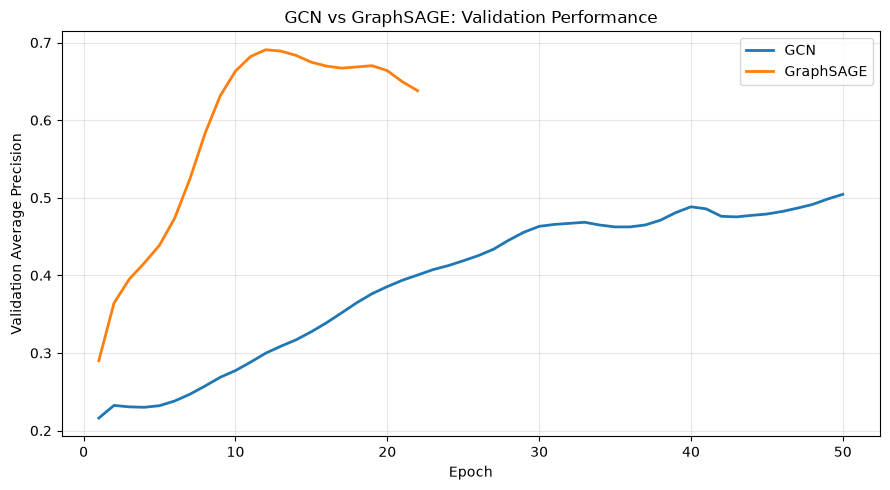

In [11]:

import pandas as pd
import matplotlib.pyplot as plt

gcn_df = pd.DataFrame(history)
sage_df = pd.DataFrame(sage_history)

plt.figure(figsize=(9, 5))

plt.plot(
    gcn_df["epoch"],
    gcn_df["pr_auc"],
    label="GCN",
    linewidth=2
)

plt.plot(
    sage_df["epoch"],
    sage_df["pr_auc"],
    label="GraphSAGE",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Validation Average Precision")
plt.title("GCN vs GraphSAGE: Validation Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

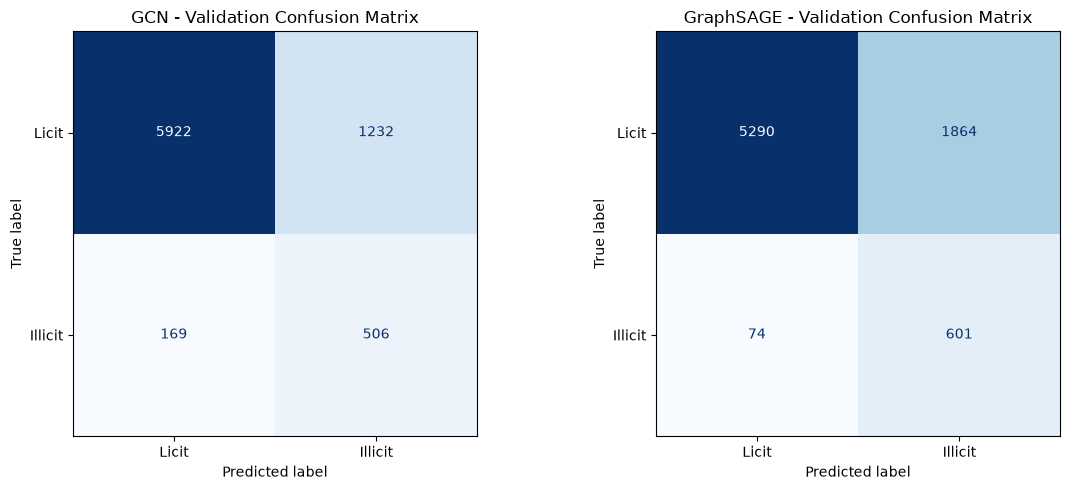

In [12]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

@torch.no_grad()
def get_predictions(model, mask):
    model.eval()

    logits = model(data.x, data.edge_index)[mask]
    probabilities = torch.softmax(logits, dim=1)[:, 1]

    y_true = data.y[mask].cpu().numpy()
    y_pred = (probabilities.cpu().numpy() >= 0.5).astype(int)

    return y_true, y_pred

# Predictions from restored best checkpoints
gcn_true, gcn_pred = get_predictions(model, data.val_mask)
sage_true, sage_pred = get_predictions(sage_model, data.val_mask)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name, y_true, y_pred in [
    (axes[0], "GCN", gcn_true, gcn_pred),
    (axes[1], "GraphSAGE", sage_true, sage_pred)
]:
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Licit", "Illicit"]
    )

    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} - Validation Confusion Matrix")

plt.tight_layout()
plt.show()

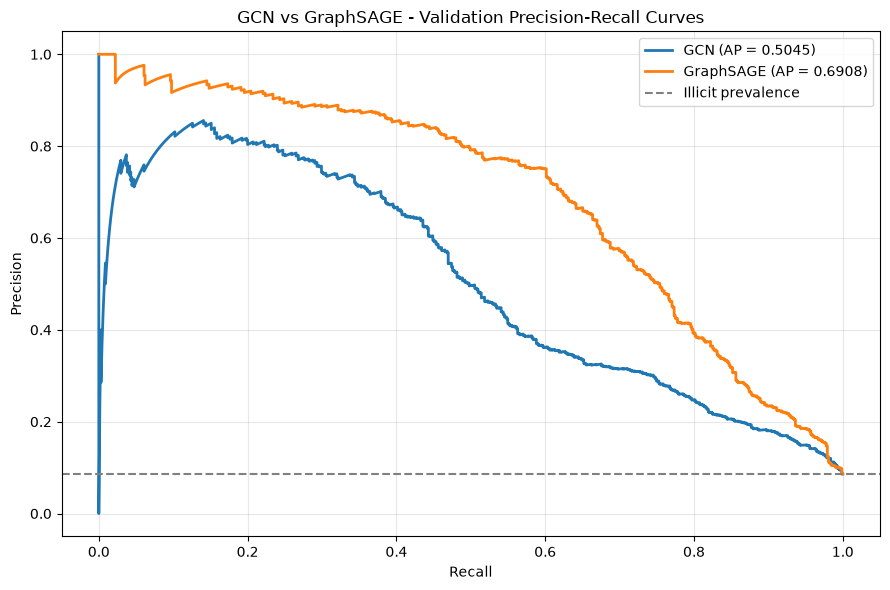

In [13]:

from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

@torch.no_grad()
def get_probabilities(model, mask):
    model.eval()
    logits = model(data.x, data.edge_index)[mask]

    probabilities = torch.softmax(
        logits, dim=1
    )[:, 1].cpu().numpy()

    labels = data.y[mask].cpu().numpy()

    return labels, probabilities

gcn_y, gcn_probs = get_probabilities(model, data.val_mask)
sage_y, sage_probs = get_probabilities(sage_model, data.val_mask)

plt.figure(figsize=(9, 6))

for name, labels, probs in [
    ("GCN", gcn_y, gcn_probs),
    ("GraphSAGE", sage_y, sage_probs)
]:
    precision, recall, _ = precision_recall_curve(labels, probs)
    ap = average_precision_score(labels, probs)

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (AP = {ap:.4f})"
    )

plt.axhline(
    y=gcn_y.mean(),
    linestyle="--",
    color="gray",
    label="Illicit prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("GCN vs GraphSAGE - Validation Precision-Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()